In [ ]:
data = load_all(use_cache=True)

train = data["train"]
val = data["val"]
test = data["test"]
modules = data["modules"]
val_sol = data["val_solution"]
sample_sub = data["sample_submission"]

print(f"train={len(train)}, val={len(val)}, test={len(test)}, modules={len(modules)}")

[data_loader] Данные загружены из кэша.
train=5002, val=3043, test=4306, modules=322


In [ ]:
train_ids = {s["student_id"] for s in train}
val_ids = {s["id"] for s in val}
test_ids = {s["id"] for s in test}

print(f"Уникальных студентов в train: {len(train_ids)}")
print(f"Уникальных студентов в val:   {len(val_ids)}")
print(f"Уникальных студентов в test:  {len(test_ids)}")
print()
print(f"train ∩ val:  {len(train_ids & val_ids)}")
print(f"train ∩ test: {len(train_ids & test_ids)}")
print(f"val ∩ test:   {len(val_ids & test_ids)}")
print(f"train ∩ val ∩ test: {len(train_ids & val_ids & test_ids)}")

Уникальных студентов в train: 5002
Уникальных студентов в val:   3043
Уникальных студентов в test:  4306

train ∩ val:  2955
train ∩ test: 2734
val ∩ test:   2741
train ∩ val ∩ test: 2685


In [ ]:
# Сравним историю одного студента в train и val
common_id = next(iter(train_ids & val_ids))
print(f"Проверяем студента {common_id}\n")

train_rec = next(s for s in train if s["student_id"] == common_id)
val_rec = next(s for s in val if s["id"] == common_id)

print(f"train.profile == val.profile: {train_rec['profile'] == val_rec['profile']}")
print(f"train.history == val.history: {train_rec['history'] == val_rec['history']}")
print()
print("train.history:", train_rec["history"])
print()
print("val.history:  ", val_rec["history"])

Проверяем студента s_002740

train.profile == val.profile: True
train.history == val.history: True

train.history: [{'period': 1, 'choices': [{'module_id': 'm_040', 'priority': 1}, {'module_id': 'm_017', 'priority': 2}, {'module_id': 'm_282', 'priority': 3}, {'module_id': 'm_037', 'priority': 4}, {'module_id': 'm_031', 'priority': 5}]}, {'period': 2, 'choices': [{'module_id': 'm_010', 'priority': 1}, {'module_id': 'm_041', 'priority': 2}, {'module_id': 'm_119', 'priority': 3}, {'module_id': 'm_162', 'priority': 4}, {'module_id': 'm_225', 'priority': 5}]}]

val.history:   [{'period': 1, 'choices': [{'module_id': 'm_040', 'priority': 1}, {'module_id': 'm_017', 'priority': 2}, {'module_id': 'm_282', 'priority': 3}, {'module_id': 'm_037', 'priority': 4}, {'module_id': 'm_031', 'priority': 5}]}, {'period': 2, 'choices': [{'module_id': 'm_010', 'priority': 1}, {'module_id': 'm_041', 'priority': 2}, {'module_id': 'm_119', 'priority': 3}, {'module_id': 'm_162', 'priority': 4}, {'module_id': 'm

In [ ]:
# Проверим: сколько модулей доступно в каждом периоде по каталогу
period_to_modules = defaultdict(set)
for m in modules:
    for p in m["available_in_periods"]:
        period_to_modules[p].add(m["module_id"])

print("[Каталог: сколько модулей доступно в каждом периоде]")
for p in sorted(period_to_modules):
    print(f"  period {p}: {len(period_to_modules[p])} модулей")
print()

# Сравним с available_modules у val
n_avail = [len(s["available_modules"]) for s in val]
print(f"val available_modules: min={min(n_avail)}, max={max(n_avail)}, avg={np.mean(n_avail):.1f}")

# Догадка: available_modules — это пересечение (модули целевого периода) ∩ (какой-то фильтр по студенту)

[Каталог: сколько модулей доступно в каждом периоде]
  period 1: 196 модулей
  period 2: 174 модулей
  period 3: 159 модулей
  period 4: 158 модулей

val available_modules: min=159, max=159, avg=159.0


In [ ]:
def parse_ground_truth(s: str) -> list[tuple[str, int]]:
    """'m_102:1 m_103:2 ...' → [('m_102', 1), ('m_103', 2), ...]"""
    out = []
    for chunk in s.split():
        mod, prio = chunk.split(":")
        out.append((mod, int(prio)))
    return out

val_sol_map = {row["id"]: parse_ground_truth(row["ground_truth"]) for _, row in val_sol.iterrows()}

# Проверим, все ли ground truth модули есть в available_modules
n_in = 0
n_out = 0
for s in val:
    avail = set(s["available_modules"])
    gt = val_sol_map.get(s["id"], [])
    for mod, _ in gt:
        if mod in avail:
            n_in += 1
        else:
            n_out += 1

print(f"Ground truth модулей в available:     {n_in}")
print(f"Ground truth модулей НЕ в available:  {n_out}")

Ground truth модулей в available:     15215
Ground truth модулей НЕ в available:  0


In [ ]:
pop = Counter()
for s in train:
    for h in s.get("history", []):
        for c in h.get("choices", []):
            pop[c["module_id"]] += 1

mod_title = {m["module_id"]: m["title"] for m in modules}

print(f"Всего модулей в каталоге: {len(modules)}")
print(f"Модулей, выбранных хотя бы раз: {len(pop)}")
print(f"Модулей, НЕ выбранных ни разу: {len(modules) - len(pop)}")
print()
print("[Топ-15 популярных модулей]")
for mod, cnt in pop.most_common(15):
    print(f"  {mod}  {cnt:>5}  {mod_title.get(mod, '?')[:60]}")
print()
print("[Топ-5 НЕпопулярных (могут быть ни разу не выбраны)]")
for mod, cnt in pop.most_common()[-5:]:
    print(f"  {mod}  {cnt:>5}  {mod_title.get(mod, '?')[:60]}")

Всего модулей в каталоге: 322
Модулей, выбранных хотя бы раз: 248
Модулей, НЕ выбранных ни разу: 74

[Топ-15 популярных модулей]
  m_206    872  Психология конфликта
  m_092    795  История кинематографа
  m_119    696  Лидерство как личная стратегия
  m_135    665  Молодая семья
  m_208    633  Психология межличностных отношений
  m_212    595  Психология человеческой судьбы
  m_039    578  Брак или развод и девичья фамилия
  m_204    558  Психология здоровья и благополучия
  m_282    549  Философия, мультфильмы и кино
  m_053    547  Восток: философия для жизни
  m_142    537  Навыки современного педагога
  m_197    508  Профессионально-личностное развитие педагога
  m_225    503  Религия и современный мир
  m_035    466  Арт-практика
  m_224    461  Режиссура телероликов для YouTube. Кино и Анимация

[Топ-5 НЕпопулярных (могут быть ни разу не выбраны)]
  m_100      9  Как подготовить нововведения и изменения в образовательной о
  m_088      8  Искусство как педагогический инструмент

In [ ]:
n_periods_train = Counter(len(s.get("history", [])) for s in train)
print(f"[train] Сколько периодов истории у студентов:")
for k in sorted(n_periods_train):
    print(f"  {k} период(ов): {n_periods_train[k]} студентов")

n_periods_val = Counter(len(s.get("history", [])) for s in val)
print(f"\n[val] Сколько периодов истории у студентов:")
for k in sorted(n_periods_val):
    print(f"  {k} период(ов): {n_periods_val[k]} студентов")

n_periods_test = Counter(len(s.get("history", [])) for s in test)
print(f"\n[test] Сколько периодов истории у студентов:")
for k in sorted(n_periods_test):
    print(f"  {k} период(ов): {n_periods_test[k]} студентов")

[train] Сколько периодов истории у студентов:
  1 период(ов): 1899 студентов
  2 период(ов): 3103 студентов

[val] Сколько периодов истории у студентов:
  0 период(ов): 88 студентов
  1 период(ов): 1531 студентов
  2 период(ов): 1424 студентов

[test] Сколько периодов истории у студентов:
  0 период(ов): 1516 студентов
  1 период(ов): 87 студентов
  2 период(ов): 1393 студентов
  3 период(ов): 1310 студентов


In [ ]:
# Сколько раз в available_modules есть модуль, который студент уже выбирал?
n_overlap = []
for s in val:
    avail = set(s["available_modules"])
    hist_mods = {
        c["module_id"]
        for h in s.get("history", [])
        for c in h.get("choices", [])
    }
    n_overlap.append(len(avail & hist_mods))

print(f"[val] Пересечение available_modules с историей:")
print(f"  min={min(n_overlap)}, max={max(n_overlap)}, avg={np.mean(n_overlap):.1f}")
print(f"  У {sum(1 for x in n_overlap if x == 0)} студентов пересечений нет")

[val] Пересечение available_modules с историей:
  min=0, max=10, avg=4.0
  У 111 студентов пересечений нет


In [11]:
# Группируем студентов val по институту и смотрим, как различается available
inst_to_avail = defaultdict(set)  # institute → set of avail tuples
inst_counts = Counter()

for s in val:
    inst = (s.get("profile") or {}).get("institute", "UNKNOWN")
    inst_counts[inst] += 1
    inst_to_avail[inst].add(tuple(sorted(s["available_modules"])))

print("[val] Институты и уникальные наборы available_modules:")
for inst, cnt in inst_counts.most_common():
    print(f"  {cnt:>4} студентов  {len(inst_to_avail[inst]):>3} уникальных наборов  {inst}")

[val] Институты и уникальные наборы available_modules:
  1041 студентов    1 уникальных наборов  Институт иностранных языков
   516 студентов    1 уникальных наборов  Институт гуманитарных наук
   306 студентов    1 уникальных наборов  Институт естествознания и спортивных технологий
   302 студентов    1 уникальных наборов  Институт педагогики и психологии образования
   243 студентов    1 уникальных наборов  Институт культуры и искусств
   202 студентов    1 уникальных наборов  Институт цифрового образования
   176 студентов    1 уникальных наборов  Институт экономики, управления и права
   169 студентов    1 уникальных наборов  Институт психологии и комплексной реабилитации
    88 студентов    1 уникальных наборов  


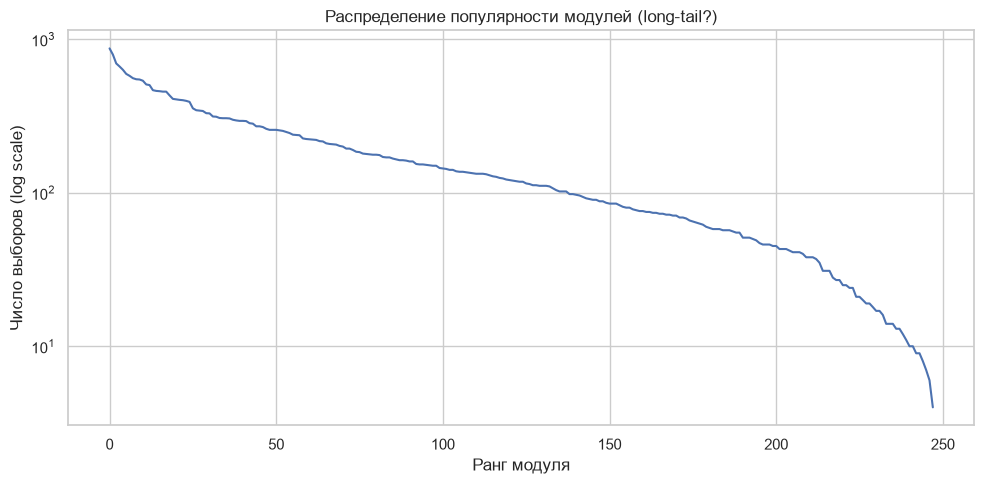

Топ-10 покрывает 16.0% всех выборов
Топ-20 покрывает 27.6% всех выборов
Топ-50 покрывает 51.1% всех выборов
Топ-100 покрывает 74.8% всех выборов


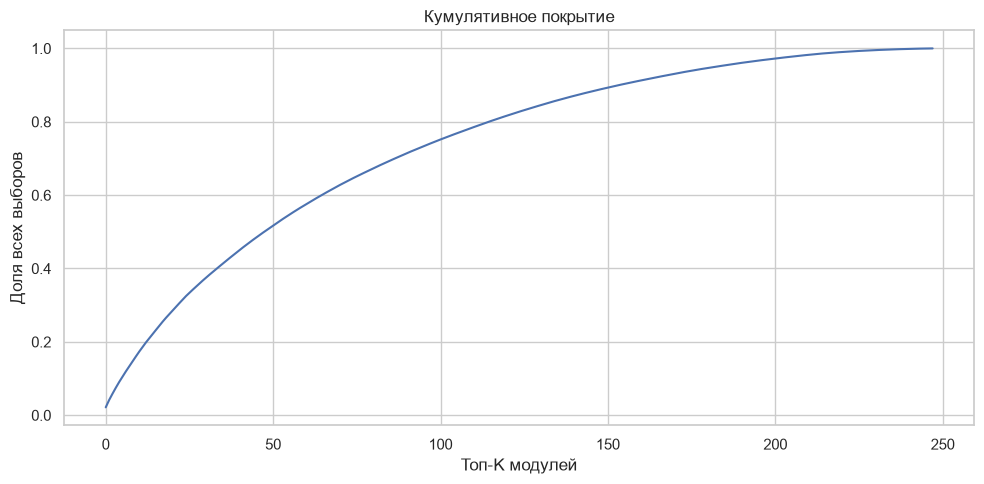

In [12]:
cnts = sorted(pop.values(), reverse=True)
plt.figure()
plt.plot(cnts)
plt.yscale("log")
plt.xlabel("Ранг модуля")
plt.ylabel("Число выборов (log scale)")
plt.title("Распределение популярности модулей (long-tail?)")
plt.tight_layout()
plt.show()

# Доля выборов, которую покрывает топ-K модулей
total = sum(cnts)
cum = np.cumsum(cnts) / total
plt.figure()
plt.plot(cum)
plt.xlabel("Топ-K модулей")
plt.ylabel("Доля всех выборов")
plt.title("Кумулятивное покрытие")
for k in [10, 20, 50, 100]:
    print(f"Топ-{k} покрывает {100 * cum[k-1]:.1f}% всех выборов")
plt.tight_layout()
plt.show()